/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


✅ Model Loaded Successfully

📤 Upload Plant Leaf Image



Saving Screenshot 2026-05-07 054738.png to Screenshot 2026-05-07 054738.png

✅ Uploaded Image: Screenshot 2026-05-07 054738.png


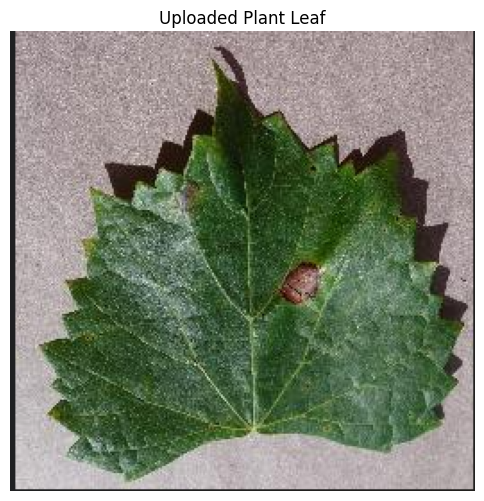


🌿 Predicted Disease : Grape___Black_rot
✅ Confidence        : 98.79%

🔍 TOP 3 PREDICTIONS

1. Grape___Black_rot
   Confidence: 98.79%

2. Grape___Esca_(Black_Measles)
   Confidence: 1.21%

3. Grape___healthy
   Confidence: 0.00%



In [ ]:
# ============================================
# FINAL WORKING TESTING SCRIPT
# ============================================

import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import transforms, models
from PIL import Image
import matplotlib.pyplot as plt
from google.colab import files

# ============================================
# DEVICE
# ============================================
device = torch.device("cpu")

# ============================================
# ALL 38 CLASSES
# ============================================
class_names = [
    'Apple___Apple_scab',
    'Apple___Black_rot',
    'Apple___Cedar_apple_rust',
    'Apple___healthy',
    'Blueberry___healthy',
    'Cherry_(including_sour)___Powdery_mildew',
    'Cherry_(including_sour)___healthy',
    'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot',
    'Corn_(maize)___Common_rust_',
    'Corn_(maize)___Northern_Leaf_Blight',
    'Corn_(maize)___healthy',
    'Grape___Black_rot',
    'Grape___Esca_(Black_Measles)',
    'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)',
    'Grape___healthy',
    'Orange___Haunglongbing_(Citrus_greening)',
    'Peach___Bacterial_spot',
    'Peach___healthy',
    'Pepper,_bell___Bacterial_spot',
    'Pepper,_bell___healthy',
    'Potato___Early_blight',
    'Potato___Late_blight',
    'Potato___healthy',
    'Raspberry___healthy',
    'Soybean___healthy',
    'Squash___Powdery_mildew',
    'Strawberry___Leaf_scorch',
    'Strawberry___healthy',
    'Tomato___Bacterial_spot',
    'Tomato___Early_blight',
    'Tomato___Late_blight',
    'Tomato___Leaf_Mold',
    'Tomato___Septoria_leaf_spot',
    'Tomato___Spider_mites Two-spotted_spider_mite',
    'Tomato___Target_Spot',
    'Tomato___Tomato_Yellow_Leaf_Curl_Virus',
    'Tomato___Tomato_mosaic_virus',
    'Tomato___healthy'
]

# ============================================
# LOAD MODEL
# ============================================
model = models.mobilenet_v2(pretrained=False)

# Change final layer
model.classifier[1] = nn.Linear(
    model.last_channel,
    len(class_names)
)

# ============================================
# LOAD SAVED WEIGHTS
# ============================================
model.load_state_dict(
    torch.load(
        "plant_disease_model.pth",
        map_location=device
    )
)

model = model.to(device)

# Evaluation mode
model.eval()

print("✅ Model Loaded Successfully")

# ============================================
# IMAGE TRANSFORM
# ============================================
transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor()
])

# ============================================
# UPLOAD IMAGE
# ============================================
print("\n📤 Upload Plant Leaf Image\n")

uploaded = files.upload()

# Uploaded image name
img_path = list(uploaded.keys())[0]

print(f"\n✅ Uploaded Image: {img_path}")

# ============================================
# LOAD IMAGE
# ============================================
img = Image.open(img_path).convert("RGB")

# Show image
plt.figure(figsize=(6,6))
plt.imshow(img)
plt.axis("off")
plt.title("Uploaded Plant Leaf")
plt.show()

# ============================================
# PREPROCESS IMAGE
# ============================================
img_tensor = transform(img)

# Add batch dimension
img_tensor = img_tensor.unsqueeze(0).to(device)

# ============================================
# PREDICTION
# ============================================
with torch.no_grad():

    outputs = model(img_tensor)

    # Convert logits to probabilities
    probs = F.softmax(outputs[0], dim=0)

    # Top 3 predictions
    top_probs, top_classes = torch.topk(probs, 3)

# ============================================
# BEST RESULT
# ============================================
best_idx = top_classes[0].item()

predicted_disease = class_names[best_idx]

confidence = top_probs[0].item() * 100

# ============================================
# FINAL RESULT
# ============================================
print("\n======================================")
print(f"🌿 Predicted Disease : {predicted_disease}")
print(f"✅ Confidence        : {confidence:.2f}%")
print("======================================")

# ============================================
# TOP 3 RESULTS
# ============================================
print("\n🔍 TOP 3 PREDICTIONS\n")

for i in range(3):

    disease = class_names[top_classes[i].item()]

    conf = top_probs[i].item() * 100

    print(f"{i+1}. {disease}")
    print(f"   Confidence: {conf:.2f}%\n")

In [ ]:
import kagglehub
import os
from torchvision import datasets, transforms

# Download dataset
path = kagglehub.dataset_download("mohitsingh1804/plantvillage")

# Find train folder
train_dir = None

for root, dirs, files in os.walk(path):
    if "train" in dirs:
        train_dir = os.path.join(root, "train")

print("Train dir:", train_dir)

# Dummy transform
transform = transforms.Compose([
    transforms.Resize((128,128)),
    transforms.ToTensor()
])

# Load dataset
train_dataset = datasets.ImageFolder(train_dir, transform=transform)

# Get classes
class_names = train_dataset.classes

print("Total Classes:", len(class_names))
print(class_names)

100%|██████████| 818M/818M [00:10<00:00, 83.5MB/s]

Extracting files...


Train dir: /root/.cache/kagglehub/datasets/mohitsingh1804/plantvillage/versions/1/PlantVillage/train
Total Classes: 38
['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy', 'Cherry_(including_sour)___Powdery_mildew', 'Cherry_(including_sour)___healthy', 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 'Corn_(maize)___Common_rust_', 'Corn_(maize)___Northern_Leaf_Blight', 'Corn_(maize)___healthy', 'Grape___Black_rot', 'Grape___Esca_(Black_Measles)', 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)', 'Grape___healthy', 'Orange___Haunglongbing_(Citrus_greening)', 'Peach___Bacterial_spot', 'Peach___healthy', 'Pepper,_bell___Bacterial_spot', 'Pepper,_bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Raspberry___healthy', 'Soybean___healthy', 'Squash___Powdery_mildew', 'Strawberry___Leaf_scorch', 'Strawberry___healthy', 'Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___Late_blight', 'T

✅ Model Loaded Successfully

📤 Upload Plant Leaf Image



Saving Screenshot 2026-05-07 060710.png to Screenshot 2026-05-07 060710.png

✅ Uploaded Image: Screenshot 2026-05-07 060710.png


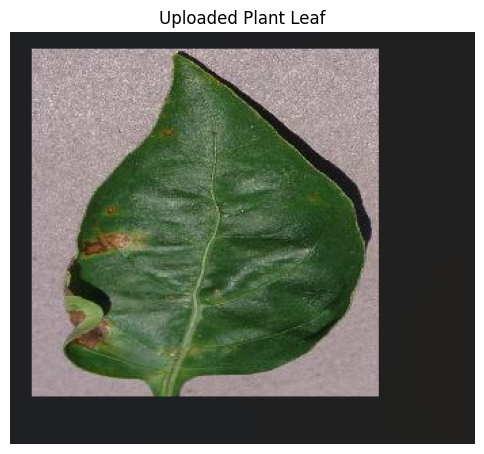


🌿 Predicted Disease : Pepper,_bell___Bacterial_spot
✅ Confidence        : 45.74%

🔍 TOP 3 PREDICTIONS

1. Pepper,_bell___Bacterial_spot
   Confidence: 45.74%

2. Tomato___Late_blight
   Confidence: 29.24%

3. Pepper,_bell___healthy
   Confidence: 9.58%

Do you want to test another image? (yes/no): yes

📤 Upload Plant Leaf Image



Saving Screenshot 2026-05-07 060741.png to Screenshot 2026-05-07 060741.png

✅ Uploaded Image: Screenshot 2026-05-07 060741.png


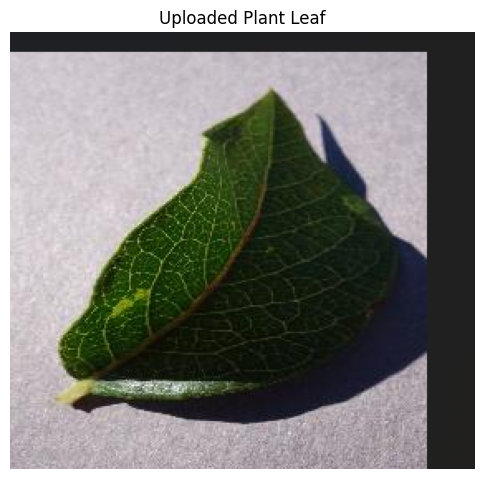


🌿 Predicted Disease : Blueberry___healthy
✅ Confidence        : 99.98%

🔍 TOP 3 PREDICTIONS

1. Blueberry___healthy
   Confidence: 99.98%

2. Apple___healthy
   Confidence: 0.01%

3. Grape___Esca_(Black_Measles)
   Confidence: 0.01%

Do you want to test another image? (yes/no): yes

📤 Upload Plant Leaf Image



Saving Screenshot 2026-05-07 060729.png to Screenshot 2026-05-07 060729.png

✅ Uploaded Image: Screenshot 2026-05-07 060729.png


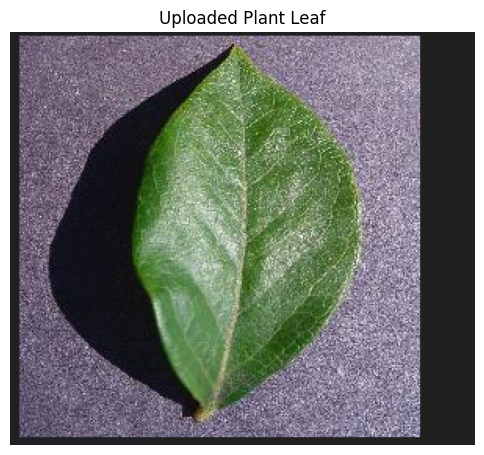


🌿 Predicted Disease : Blueberry___healthy
✅ Confidence        : 99.25%

🔍 TOP 3 PREDICTIONS

1. Blueberry___healthy
   Confidence: 99.25%

2. Strawberry___healthy
   Confidence: 0.67%

3. Tomato___Late_blight
   Confidence: 0.02%

Do you want to test another image? (yes/no): no

✅ Program Ended


In [ ]:
# ============================================
# PLANT DISEASE DETECTION - LOOP VERSION
# ============================================

import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import transforms, models
from PIL import Image
import matplotlib.pyplot as plt
from google.colab import files

# ============================================
# DEVICE
# ============================================
device = torch.device("cpu")

# ============================================
# CLASS NAMES
# ============================================
class_names = [
    'Apple___Apple_scab',
    'Apple___Black_rot',
    'Apple___Cedar_apple_rust',
    'Apple___healthy',
    'Blueberry___healthy',
    'Cherry_(including_sour)___Powdery_mildew',
    'Cherry_(including_sour)___healthy',
    'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot',
    'Corn_(maize)___Common_rust_',
    'Corn_(maize)___Northern_Leaf_Blight',
    'Corn_(maize)___healthy',
    'Grape___Black_rot',
    'Grape___Esca_(Black_Measles)',
    'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)',
    'Grape___healthy',
    'Orange___Haunglongbing_(Citrus_greening)',
    'Peach___Bacterial_spot',
    'Peach___healthy',
    'Pepper,_bell___Bacterial_spot',
    'Pepper,_bell___healthy',
    'Potato___Early_blight',
    'Potato___Late_blight',
    'Potato___healthy',
    'Raspberry___healthy',
    'Soybean___healthy',
    'Squash___Powdery_mildew',
    'Strawberry___Leaf_scorch',
    'Strawberry___healthy',
    'Tomato___Bacterial_spot',
    'Tomato___Early_blight',
    'Tomato___Late_blight',
    'Tomato___Leaf_Mold',
    'Tomato___Septoria_leaf_spot',
    'Tomato___Spider_mites Two-spotted_spider_mite',
    'Tomato___Target_Spot',
    'Tomato___Tomato_Yellow_Leaf_Curl_Virus',
    'Tomato___Tomato_mosaic_virus',
    'Tomato___healthy'
]

# ============================================
# LOAD MODEL
# ============================================
model = models.mobilenet_v2(pretrained=False)

model.classifier[1] = nn.Linear(
    model.last_channel,
    len(class_names)
)

# ============================================
# LOAD TRAINED MODEL
# ============================================
model.load_state_dict(
    torch.load(
        "plant_disease_model.pth",
        map_location=device
    )
)

model = model.to(device)

# Evaluation mode
model.eval()

print("✅ Model Loaded Successfully")

# ============================================
# IMAGE TRANSFORM
# ============================================
transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor()
])

# ============================================
# LOOP FOR MULTIPLE PREDICTIONS
# ============================================
while True:

    print("\n📤 Upload Plant Leaf Image\n")

    uploaded = files.upload()

    # Get uploaded image name
    img_path = list(uploaded.keys())[0]

    print(f"\n✅ Uploaded Image: {img_path}")

    # ========================================
    # LOAD IMAGE
    # ========================================
    img = Image.open(img_path).convert("RGB")

    # Show image
    plt.figure(figsize=(6,6))
    plt.imshow(img)
    plt.axis("off")
    plt.title("Uploaded Plant Leaf")
    plt.show()

    # ========================================
    # PREPROCESS IMAGE
    # ========================================
    img_tensor = transform(img)

    # Add batch dimension
    img_tensor = img_tensor.unsqueeze(0).to(device)

    # ========================================
    # PREDICTION
    # ========================================
    with torch.no_grad():

        outputs = model(img_tensor)

        # Convert logits to probabilities
        probs = F.softmax(outputs[0], dim=0)

        # Top 3 predictions
        top_probs, top_classes = torch.topk(probs, 3)

    # ========================================
    # BEST RESULT
    # ========================================
    best_idx = top_classes[0].item()

    predicted_disease = class_names[best_idx]

    confidence = top_probs[0].item() * 100

    # ========================================
    # FINAL OUTPUT
    # ========================================
    print("\n======================================")
    print(f"🌿 Predicted Disease : {predicted_disease}")
    print(f"✅ Confidence        : {confidence:.2f}%")
    print("======================================")

    # ========================================
    # TOP 3 RESULTS
    # ========================================
    print("\n🔍 TOP 3 PREDICTIONS\n")

    for i in range(3):

        disease = class_names[top_classes[i].item()]

        conf = top_probs[i].item() * 100

        print(f"{i+1}. {disease}")
        print(f"   Confidence: {conf:.2f}%\n")

    # ========================================
    # ASK USER TO CONTINUE
    # ========================================
    choice = input("Do you want to test another image? (yes/no): ")

    if choice.lower() != "yes":
        print("\n✅ Program Ended")
        break